In [1]:
import sys
from pathlib import Path

# Permite importar lista4 desde la carpeta src
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lista4.data import load_csv
from lista4.models import linear_summary
from lista4.metrics import corr_pair

df = load_csv("experimento_1")
df.head()

,x1,x2,y
0,0.304717,1.727350,1.429562
1,-1.039984,-1.533861,-3.697491
2,0.750451,0.863828,3.525801
3,0.940565,-0.328525,2.194107
4,-1.951035,-0.061324,-6.489721


In [2]:
#A
especificaciones = {
    "x1 -> y": ["x1"],
    "x2 -> y": ["x2"],
    "(x1, x2) -> y": ["x1", "x2"],
}

resultados = {
    nombre: linear_summary(df, cols, "y", label=nombre)
    for nombre, cols in especificaciones.items()
}

tabla = pd.DataFrame(
    [{k: v for k, v in r.items() if not k.startswith("_")} for r in resultados.values()]
).set_index("modelo")
tabla

,intercepto,coef_x1,riesgo_empirico,coef_x2
modelo,,,,
x1 -> y,-0.082506,2.92046,1.020069,NaN
x2 -> y,-0.202971,NaN,8.374587,-0.044049
"(x1, x2) -> y",-0.083790,2.92513,1.002351,-0.131194


### (a) Tabla de modelos

| Modelo | Intercepto | Coeficientes | Riesgo empírico |
|---|---|---|---|
| x1 → y | -0.0825 | β₁ = 2.9205 | 1.0201 |
| x2 → y | -0.2030 | β₂ = -0.0440 | 8.3746 |
| (x1, x2) → y | -0.0838 | β₁ = 2.9251, β₂ = -0.1312 | 1.0024 |

El modelo con `x1` tiene un riesgo empírico mucho menor (1.02) que el modelo con `x2` (8.37), así que `x1` explica mucho mejor a `y`. El modelo con ambas variables baja el riesgo solo a 1.0024, una mejora muy pequeña respecto a usar únicamente `x1`. Además, el coeficiente de `x1` casi no cambia al agregar `x2` (2.9205 frente a 2.9251). Como conclusión se puede decir que `x1` explica en su mayoria a `y` ya que cuando`x1` sube una unidad `y`sube 2,9, en cambio `x2` casi no mueve a `y`.  

In [3]:
#B
correlaciones = pd.Series({
    "corr(x1, y)": corr_pair(df, "x1", "y"),
    "corr(x2, y)": corr_pair(df, "x2", "y"),
    "corr(x1, x2)": corr_pair(df, "x1", "x2"),
}, name="correlación")

correlaciones.to_frame()

,correlación
"corr(x1, y)",0.937136
"corr(x2, y)",-0.015450
"corr(x1, x2)",0.032563


### (b) Correlaciones

| Pareja | Correlación |
|---|---|
| corr(x1, y) | 0.937 |
| corr(x2, y) | -0.015 |
| corr(x1, x2) | 0.033 |

- `x1` y `y` tienen una relación lineal fuerte y positiva (0.937): cuando `x1` aumenta, `y` tiende a aumentar.
- `x2` y `y` casi no tienen relación lineal (-0.015, prácticamente cero), lo que explica su riesgo alto y su pendiente cercana a cero.

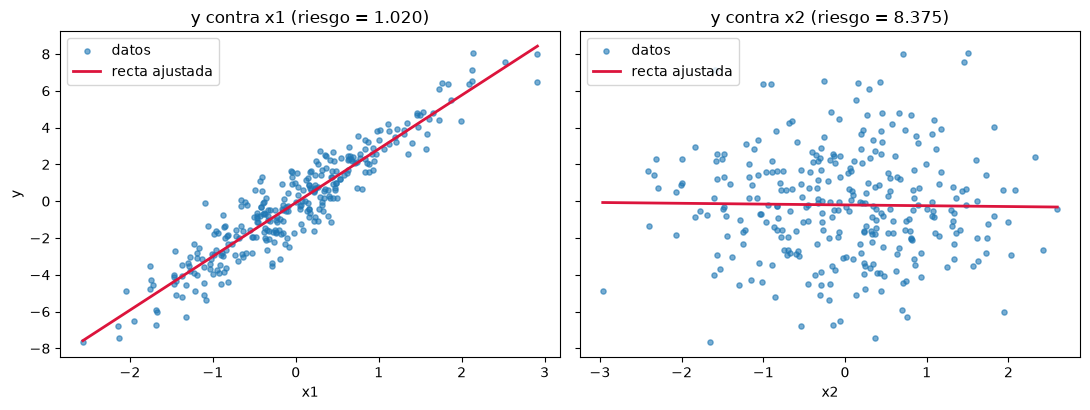

In [4]:
#C
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)

for ax, var in zip(axes, ["x1", "x2"]):
    r = resultados[f"{var} -> y"]

    # Dos puntos extremos bastan para trazar una recta; usamos 100 para que quede suave
    xs = np.linspace(df[var].min(), df[var].max(), 100)
    ys = r["intercepto"] + r["coef_" + var] * xs

    ax.scatter(df[var], df["y"], s=14, alpha=0.6, label="datos")
    ax.plot(xs, ys, color="crimson", lw=2, label="recta ajustada")
    ax.set_xlabel(var)
    ax.set_title(f"y contra {var} (riesgo = {r['riesgo_empirico']:.3f})")
    ax.legend()

axes[0].set_ylabel("y")
plt.tight_layout()

### (c) Gráficas

- **y contra x1:** los puntos forman una nube que sube de izquierda a derecha y quedan muy cerca de la recta ajustada. La recta describe bien los datos, lo que coincide con la correlación alta (0.937) y con el riesgo empírico bajo (1.02).
- **y contra x2:** los puntos están dispersos sin un patrón claro y la recta es casi horizontal. La recta no captura la variación de `y`, lo que coincide con la correlación casi 0 y con el riesgo empírico alto (8.37).

Por lo tanto, `x1` describe mucho mejor a `y` que `x2`.

### (d) 

Con el criterio del menor riesgo empírico entre los modelos de una sola variable:

| Modelo | Riesgo empírico |
|---|---|
| x1 → y | 1.0201 |
| x2 → y | 8.3746 |

Se conserva **`x1`**, porque su modelo tiene un riesgo empírico mucho menor. Es coherente con la correlación del inciso b. Además, agregar `x2` al modelo con `x1` solo baja el riesgo de 1.0201 a 1.0024, así que `x2` aporta muy poca información.